In [5]:
import pandas as pd
# Task 1 - Load a CSV file using Pandas and display basic info.
df = pd.read_excel(r"C:\path\to\copy_SQL_Sales_Dataset_200_Rows.xlsx")
print(df.head())
print("\n--- Dataset Info ---")
print(df.info())
print("\n--- Summary Statistics ---")
print(df.describe())

   order_id  customer_name order_date   category sub_category    product_name  \
0      1000    Caleb Davis 2025-01-31   Clothing        Jeans       Jeans Try   
1      1001  Misty Herrera 2025-05-05   Clothing        Jeans       Jeans New   
2      1002      Rick Soto 2025-06-09   Clothing        Shoes        Shoes Us   
3      1003      Sean Haas 2025-02-27  Furniture         Desk    Desk Section   
4      1004       Ann Hall 2025-06-01  Furniture      Cabinet  Cabinet Center   

   quantity  unit_price  total_price region  
0         2        1197         2394   West  
1         9        1509        13581  South  
2         5        1046         5230   East  
3        10         292         2920  South  
4         2         548         1096  North  

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ord

In [6]:
# Task 2 - Handle missing values and duplicates using Pandas.
print("Missing values per column:\n", df.isnull().sum())
print("\nDuplicate rows count:", df.duplicated().sum())

# also check if there are duplicate order_ids
print("Duplicate order_id count:", df["order_id"].duplicated().sum())

Missing values per column:
 order_id         0
customer_name    0
order_date       0
category         0
sub_category     0
product_name     0
quantity         0
unit_price       0
total_price      0
region           0
dtype: int64

Duplicate rows count: 0
Duplicate order_id count: 0


In [7]:
# Remove exact duplicate rows
df = df.drop_duplicates()

# handling for missing values (if any exist):
# Drop rows missing critical identifiers or amounts
df = df.dropna(subset=["order_id", "total_price"])

# Fill missing numeric values with median or 0, and missing text with "Unknown"
for col in ["quantity", "unit_price"]:
  if df[col].isnull().any():
    df[col] = df[col].fillna(df[col].median())

for col in [
    "customer_name",
    "category",
    "sub_category",
    "product_name",
    "region",
]:
  if df[col].isnull().any():
    df[col] = df[col].fillna("Unknown")

print("Shape after cleaning:", df.shape)

Shape after cleaning: (200, 10)


In [12]:
# Task 3 -  Group data by category and find total revenue
category_revenue = (
    df.groupby("category", as_index=False)["total_price"]
    .sum()
    .sort_values(by="total_price", ascending=False)
)
print("--- total_price (revenue) category-wise ---")
print(category_revenue)

category_summary = (
    df.groupby("category", as_index=False)
    .agg(
        orders=("order_id", "count"),
        total_revenue=("total_price", "sum"),
        avg_order_value=("total_price", "mean"),
    )
    .sort_values(by="total_revenue", ascending=False)
)
print("--- total no. of orders, total revenue and average order value category wise ---")
print(category_summary)

--- Category wise total_price (revenue) ---
      category  total_price
2    Furniture       714399
3      Grocery       672147
1  Electronics       549302
0     Clothing       484259
--- Category wise total no. of orders, total revenue and average order value ---
      category  orders  total_revenue  avg_order_value
2    Furniture      59         714399     12108.457627
3      Grocery      49         672147     13717.285714
1  Electronics      52         549302     10563.500000
0     Clothing      40         484259     12106.475000


In [11]:
# Task 4 - Sort data by multiple columns using Python
sorted_df = df.sort_values(
    by=["region", "total_price"], ascending=[True, False]
)

print("--- Dataset is sorted by Ascending order in region and by Descending order in total_price ---")
print(
    sorted_df[
        [
            "order_id",
            "customer_name",
            "region",
            "category",
            "quantity",
            "total_price",
        ]
    ].head(15)
)

--- Dataset is sorted by Ascending order in region and by Descending order in total_price ---
     order_id        customer_name region     category  quantity  total_price
125      1125        Lynn Garrison   East      Grocery        10        47940
160      1160     Michelle Beltran   East    Furniture         9        42471
190      1190    Christopher Meyer   East      Grocery         8        37320
167      1167          Julie Adams   East      Grocery         7        31108
115      1115          Gary Osborn   East  Electronics         9        29124
59       1059  Miss Rebecca Levine   East     Clothing         6        28764
157      1157        Patricia Gill   East     Clothing         7        27405
24       1024           Jodi Smith   East      Grocery         6        27066
6        1006     Breanna Gonzalez   East      Grocery         6        26136
96       1096        Daniel Torres   East  Electronics         7        25886
180      1180          Hailey Cobb   East     Cl

In [13]:
sorted_by_cat_date = df.sort_values(
    by=["category", "order_date"], ascending=[True, False]
)

print("--- Dataset is sorted by Ascending order in category and by Descending order in order_date ---")
print(
    sorted_by_cat_date[
        ["order_id", "category", "order_date", "total_price"]
    ].head(15)
)

--- Dataset is sorted by Ascending order in category and by Descending order in order_date ---
     order_id  category order_date  total_price
92       1092  Clothing 2025-06-16        21312
51       1051  Clothing 2025-06-13         1488
42       1042  Clothing 2025-06-10        24115
2        1002  Clothing 2025-06-09         5230
102      1102  Clothing 2025-06-05         7456
161      1161  Clothing 2025-06-02         6352
28       1028  Clothing 2025-05-23         2195
62       1062  Clothing 2025-05-21        22456
66       1066  Clothing 2025-05-15         9106
138      1138  Clothing 2025-05-09         8770
53       1053  Clothing 2025-05-06         2430
82       1082  Clothing 2025-05-06        24402
1        1001  Clothing 2025-05-05        13581
15       1015  Clothing 2025-05-05         4677
179      1179  Clothing 2025-05-01        11712


In [14]:
# Task 5 - Create a correlation matrix for numerical columns
numeric_cols = ["quantity", "unit_price", "total_price"]
corr_matrix = df[numeric_cols].corr()

print("--- Correlation Matrix ---")
print(corr_matrix)

--- Correlation Matrix ---
             quantity  unit_price  total_price
quantity     1.000000    0.047996     0.655212
unit_price   0.047996    1.000000     0.671318
total_price  0.655212    0.671318     1.000000


Matplotlib is building the font cache; this may take a moment.


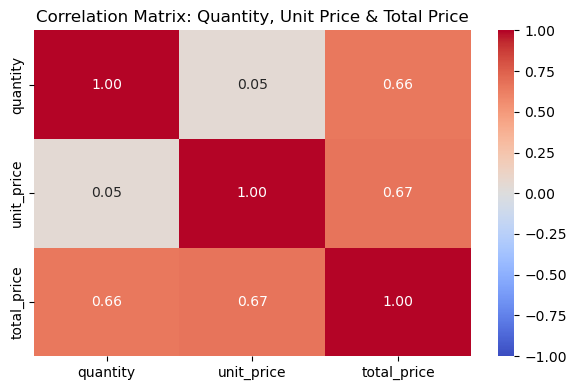

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix: Quantity, Unit Price & Total Price")
plt.tight_layout()
plt.show()